# MUSIC CLASSIFICATION

In [1]:
import json
import os
import math
import librosa
import subprocess
import time
import warnings

DATASET_PATH = "/kaggle/input/datasets/andradaolteanu/gtzan-dataset-music-genre-classification/Data/genres_original"
JSON_PATH = "/kaggle/working/data_10.json"

SAMPLE_RATE = 22050
TRACK_DURATION = 30 # measured in seconds
SAMPLES_PER_TRACK = SAMPLE_RATE * TRACK_DURATION

In [2]:
warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=FutureWarning)

### Dataset Prepaation

In [3]:


def save_mfcc(
    dataset_path,
    json_path,
    num_mfcc=13,
    n_fft=2048,
    hop_length=512,
    num_segments=10
):
    # extracting mfccs and saving them
    data = {
        "mapping": [],
        "labels": [],
        "mfcc": []
    }
    
    samples_per_segment = int(SAMPLES_PER_TRACK/num_segments)
    num_mfcc_vectors_per_segment = math.ceil(samples_per_segment/hop_length)
    
    corrupt_count = 0
    
    print("=" * 80)
    print("STARTING MFCC EXTRACTION")
    print("=" * 80)

    # Get genre folders explicitly
    genre_folders = sorted([
        folder for folder in os.listdir(dataset_path)
        if os.path.isdir(os.path.join(dataset_path, folder))
    ])

    print(f"Dataset: {dataset_path}")
    print(f"Genres found: {genre_folders}")
    print()

    # Create mapping based on genre names
    label_mapping = {
        genre: i for i, genre in enumerate(genre_folders)
    }

    data["mapping"] = genre_folders

    # Process each genre
    for genre in genre_folders:

        dirpath = os.path.join(dataset_path, genre)
        label = label_mapping[genre]

        print(f"\nProcessing: {genre}")

        filenames = sorted([
            f for f in os.listdir(dirpath)
            if f.lower().endswith(".wav")
        ])

        process_count = 0

        for f in filenames:

            file_path = os.path.join(dirpath, f)

            # Load audio
            try:
                signal, sample_rate = librosa.load(
                    file_path,
                    sr=SAMPLE_RATE
                )

            except Exception:
                print(f"\nSkipping corrupted file: {file_path}")
                corrupt_count += 1
                continue

            # Divide song into segments
            for d in range(num_segments):

                start = samples_per_segment * d
                finish = start + samples_per_segment

                # Extract MFCC
                mfcc = librosa.feature.mfcc(
                    y=signal[start:finish],
                    sr=sample_rate,
                    n_mfcc=num_mfcc,
                    n_fft=n_fft,
                    hop_length=hop_length
                )

                mfcc = mfcc.T

                # Only keep segments with expected dimensions
                if len(mfcc) == num_mfcc_vectors_per_segment:

                    data["mfcc"].append(mfcc.tolist())
                    data["labels"].append(label)

                    process_count += 1

            if process_count % 10 == 0:
                print(
                    f"\r  {f} | {process_count} segments",
                    end=""
                )

        print(f"\n  Completed {genre}: {process_count} segments")

    # Save JSON
    with open(json_path, "w") as fp:
        json.dump(data, fp, indent=4)

    print("\n" + "=" * 80)
    print("MFCC EXTRACTION COMPLETE")
    print("=" * 80)

    print(f"JSON saved to: {json_path}")
    print(f"Total segments: {len(data['mfcc'])}")
    print(f"Total labels: {len(data['labels'])}")
    print(f"Genres: {data['mapping']}")

    if corrupt_count:
        print(f"Corrupted files skipped: {corrupt_count}")
    

In [4]:
if not os.path.exists(DATASET_PATH):
    raise FileNotFoundError(
        f"Dataset not found at:\n{DATASET_PATH}"
    )

save_mfcc(
    DATASET_PATH,
    JSON_PATH,
    num_segments=10
)

STARTING MFCC EXTRACTION
Dataset: /kaggle/input/datasets/andradaolteanu/gtzan-dataset-music-genre-classification/Data/genres_original
Genres found: ['blues', 'classical', 'country', 'disco', 'hiphop', 'jazz', 'metal', 'pop', 'reggae', 'rock']


Processing: blues
  blues.00099.wav | 1000 segments
  Completed blues: 1000 segments

Processing: classical
  classical.00050.wav | 510 segments
  Completed classical: 999 segments

Processing: country
  country.00006.wav | 70 segments
  Completed country: 999 segments

Processing: disco
  disco.00013.wav | 140 segments
  Completed disco: 999 segments

Processing: hiphop
  hiphop.00031.wav | 320 segments
  Completed hiphop: 999 segments

Processing: jazz
  jazz.00053.wav | 540 segments
Skipping corrupted file: /kaggle/input/datasets/andradaolteanu/gtzan-dataset-music-genre-classification/Data/genres_original/jazz/jazz.00054.wav
  jazz.00099.wav | 990 segments
  Completed jazz: 990 segments

Processing: metal
  metal.00099.wav | 1000 segments
  C

### Training MLP Genre Classifier

In [5]:
from sklearn.model_selection import train_test_split
import tensorflow.keras as keras
import numpy as np

DATA_PATH = "/kaggle/working/data_10.json"

def load_data(data_path):
    #Loads the MFCC dataset from a JSON file.

    with open(data_path, "r") as fp:
        data = json.load(fp)

    # Convert lists to NumPy arrays
    X = np.array(data["mfcc"])
    y = np.array(data["labels"])

    print("Data successfully loaded!")
    print(f"X shape: {X.shape}")
    print(f"y shape: {y.shape}")

    return X, y


# Load data
X, y = load_data(DATA_PATH)

Data successfully loaded!
X shape: (9986, 130, 13)
y shape: (9986,)


In [6]:
 # create train/test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3)

# build network topology
model = keras.Sequential([

    # input layer
    keras.layers.Flatten(input_shape=(X.shape[1], X.shape[2])),
    
    # 1st dense layer
    keras.layers.Dense(512, activation='relu'),
    
    # 2nd dense layer
    keras.layers.Dense(256, activation='relu'),
    
    # 3rd dense layer
    keras.layers.Dense(64, activation='relu'),
    
    # output layer
    keras.layers.Dense(10, activation='softmax')
])

# compile model
optimiser = keras.optimizers.Adam(learning_rate=0.0001)
model.compile(optimizer=optimiser,
                  loss='sparse_categorical_crossentropy',
                  metrics=['accuracy'])

model.summary()

# train model
history = model.fit(X_train, y_train, validation_data=(X_test, y_test), batch_size=32, epochs=50)

2026-09-22 17:08:13.908367: E external/local_xla/xla/stream_executor/cuda/cuda_platform.cc:51] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 1690)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │       865,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │        16,448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,014,218 (3.87 MB)

 Trainable params: 1,014,218 (3.87 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/50
219/219 ━━━━━━━━━━━━━━━━━━━━ 4s 11ms/step - accuracy: 0.3323 - loss: 8.6037 - val_accuracy: 0.3718 - val_loss: 4.0534
Epoch 2/50
219/219 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - accuracy: 0.4199 - loss: 3.1395 - val_accuracy: 0.3762 - val_loss: 3.0534
Epoch 3/50
219/219 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - accuracy: 0.4688 - loss: 2.1906 - val_accuracy: 0.4439 - val_loss: 2.4660
Epoch 4/50
219/219 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - accuracy: 0.5346 - loss: 1.7136 - val_accuracy: 0.4439 - val_loss: 2.4490
Epoch 5/50
219/219 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - accuracy: 0.5893 - loss: 1.3868 - val_accuracy: 0.4316 - val_loss: 2.3334
Epoch 6/50
219/219 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - accuracy: 0.6352 - loss: 1.1879 - val_accuracy: 0.4686 - val_loss: 2.1397
Epoch 7/50
219/219 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - accuracy: 0.6724 - loss: 1.0001 - val_accuracy: 0.4880 - val_loss: 2.1377
Epoch 8/50
219/219 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - accuracy: 0.7127 - loss: 0.8888 - val_accur

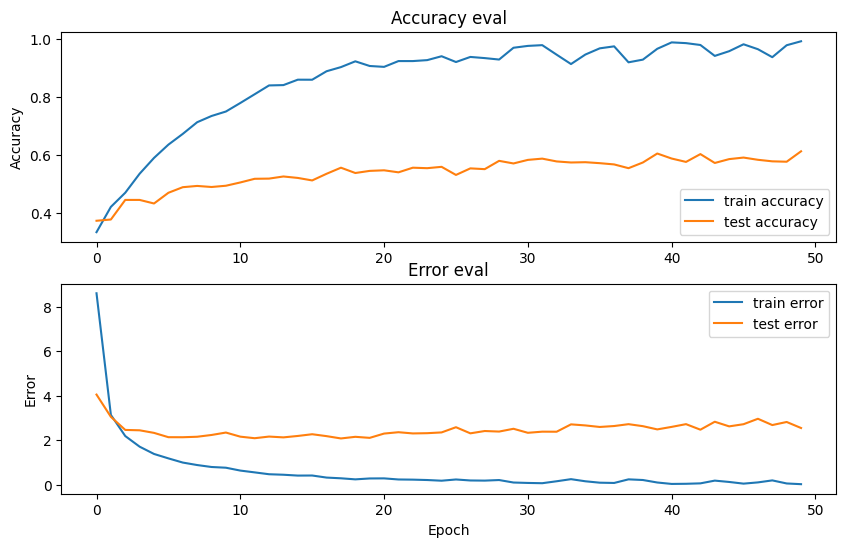

In [7]:
import matplotlib.pyplot as plt

def plot_history(history):
    fig, axs = plt.subplots(2,figsize=(10, 6))


    # create accuracy subplot
    axs[0].plot(history.history["accuracy"], label = "train accuracy")
    axs[0].plot(history.history["val_accuracy"], label = "test accuracy")
    axs[0].set_ylabel("Accuracy")
    axs[0].legend(loc="lower right")
    axs[0].set_title("Accuracy eval")

    # create error subplot
    axs[1].plot(history.history["loss"], label = "train error")
    axs[1].plot(history.history["val_loss"], label = "test error")
    axs[1].set_ylabel("Error")
    axs[1].set_xlabel("Epoch")
    axs[1].legend(loc="upper right")
    axs[1].set_title("Error eval")

    plt.show()


plot_history(history)
    

In [ ]:
# evaluate model on test set before overfitting
test_loss, test_acc = model.evaluate(X_test, y_test, verbose=2)
print('\nTest accuracy:', test_acc)

### Training model with drop out and regularization to solve overfitting

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_1 (Flatten)             │ (None, 1690)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 512)            │       865,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 64)             │        16,448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,014,218 (3.87 MB)

 Trainable params: 1,014,218 (3.87 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/50
219/219 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step - accuracy: 0.1564 - loss: 23.0954 - val_accuracy: 0.1302 - val_loss: 3.5122
Epoch 2/50
219/219 ━━━━━━━━━━━━━━━━━━━━ 3s 12ms/step - accuracy: 0.1222 - loss: 5.8723 - val_accuracy: 0.1115 - val_loss: 3.5152
Epoch 3/50
219/219 ━━━━━━━━━━━━━━━━━━━━ 3s 12ms/step - accuracy: 0.1186 - loss: 4.2027 - val_accuracy: 0.1071 - val_loss: 3.5144
Epoch 4/50
219/219 ━━━━━━━━━━━━━━━━━━━━ 3s 12ms/step - accuracy: 0.1143 - loss: 3.8472 - val_accuracy: 0.1165 - val_loss: 3.4880
Epoch 5/50
219/219 ━━━━━━━━━━━━━━━━━━━━ 3s 12ms/step - accuracy: 0.1202 - loss: 3.6974 - val_accuracy: 0.1158 - val_loss: 3.4848
Epoch 6/50
219/219 ━━━━━━━━━━━━━━━━━━━━ 3s 12ms/step - accuracy: 0.1163 - loss: 3.6166 - val_accuracy: 0.1192 - val_loss: 3.4741
Epoch 7/50
219/219 ━━━━━━━━━━━━━━━━━━━━ 3s 12ms/step - accuracy: 0.1192 - loss: 3.5679 - val_accuracy: 0.1182 - val_loss: 3.4709
Epoch 8/50
219/219 ━━━━━━━━━━━━━━━━━━━━ 3s 12ms/step - accuracy: 0.1169 - loss: 3.5477 - val_acc

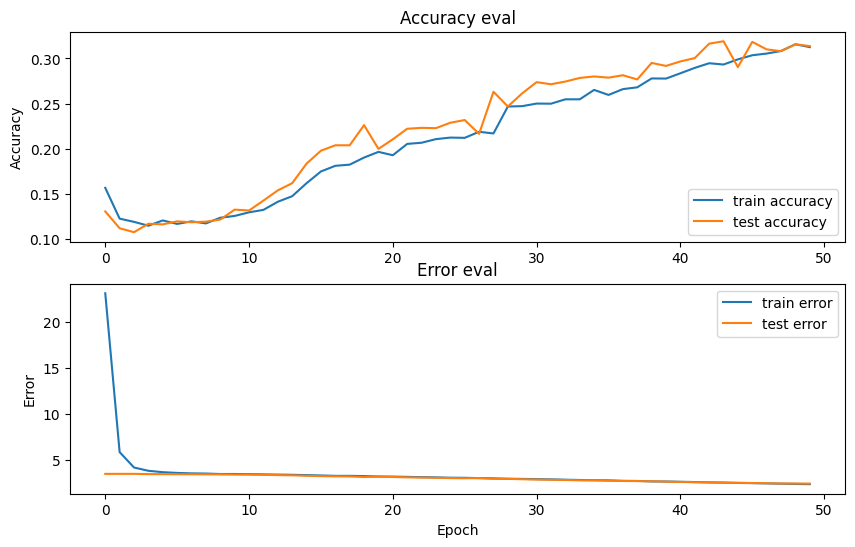

In [8]:
# build network topology
model = keras.Sequential([

    # input layer
    keras.layers.Flatten(input_shape=(X.shape[1], X.shape[2])),
    
    # 1st dense layer
    keras.layers.Dense(512, activation='relu', kernel_regularizer= keras.regularizers.l2(0.001)),
    keras.layers.Dropout(0.3),
    
    # 2nd dense layer
    keras.layers.Dense(256, activation='relu', kernel_regularizer= keras.regularizers.l2(0.001)),
    keras.layers.Dropout(0.3),
    
    # 3rd dense layer
    keras.layers.Dense(64, activation='relu', kernel_regularizer= keras.regularizers.l2(0.001)),
    keras.layers.Dropout(0.3),
    
    # output layer
    keras.layers.Dense(10, activation='softmax')
])

# compile model
optimiser = keras.optimizers.Adam(learning_rate=0.0001)
model.compile(optimizer=optimiser,
                  loss='sparse_categorical_crossentropy',
                  metrics=['accuracy'])

model.summary()

# train model
history = model.fit(X_train, y_train, validation_data=(X_test, y_test), batch_size=32, epochs=50)

# plot the performance
plot_history(history)

In [9]:
# evaluate model on test set
test_loss, test_acc = model.evaluate(X_test, y_test, verbose=2)
print('\nTest accuracy:', test_acc)

94/94 - 0s - 4ms/step - accuracy: 0.3138 - loss: 2.4578

Test accuracy: 0.3137516677379608


By reducing overfitting through drop out, our training and test performance become consistent